# Контроль конфаундеров для внешней модели

Проверяем требование ТЗ на модели, которая построена не в этом ноутбуке (её признаки и модель уже
готовы и загружаются отсюда):

1. предсказание возраста по тем же признакам внутри контрольной группы (Норма) — связь должна быть слабой;
2. метрики отдельно по возрастным подгруппам там, где возраст известен (только Норма);
3. проверка, что скор модели не сводится к одному поведенческому показателю (суммарное время решения таблиц).

Первые два пункта работают на уже готовой таблице признаков этой модели. Третий считается по сырым
данным заново, независимо от модели.

In [14]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import pickle

import mne
mne.set_log_level("ERROR")

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneOut, cross_val_predict

DATA_DIR = Path("../data/neurodiagnostics-train")   # сырые данные, для пересчёта времени решения
EXCLUDE_SUBJECTS = {"XCFU5", "PTMJ6"}

MODEL_PATH = Path("../model/model_eeg.joblib")
FEATURES_CSV = Path("../model/pipeline_features/eeg/features.csv")


ID_COLS = ["person", "group"]


def classify_file(stem: str):
    if re.search(r"(?:^|[_\-\s])(п|p|rest|покой)$", stem, re.I):
        return "rest"
    return "task"

## Загрузка модели и признаков

In [21]:
model_dict = joblib.load(MODEL_PATH)
pipe = model_dict["model"]

feat_df["score"] = pipe.predict_proba(X_all)[:, 1]

In [22]:
feat_df = pd.read_csv(FEATURES_CSV)
print(feat_df.shape)
print(feat_df[ID_COLS].head())

X_cols = [c for c in feat_df.columns if c not in ID_COLS]
print("признаков:", len(X_cols))

X_all = feat_df[X_cols].values
feat_df["score"] = pipe.predict_proba(X_all)[:, 1]
print(feat_df[["group", "score"]].groupby("group").describe())

(165, 17)
     person  group
0  КС010_19  Норма
1  КС011_25  Норма
2  КС012_58  Норма
3  КС013_23  Норма
4  КС014_22  Норма
признаков: 15
              score                                                    \
              count      mean       std       min       25%       50%   
group                                                                   
Норма          67.0  0.326653  0.208238  0.091809  0.165795  0.255957   
ПТСР           25.0  0.634728  0.132474  0.351422  0.544568  0.654500   
Соматоформные  73.0  0.400727  0.279047  0.020865  0.075221  0.433952   

                                   
                    75%       max  
group                              
Норма          0.412595  0.851627  
ПТСР           0.717249  0.868151  
Соматоформные  0.653931  0.942178  


Средняя P(ПТСР) в группе ПТСР (0.635) заметно выше, чем в Норме (0.327), модель действительно различает эти две группы, направление правильное, разброс (std) у ПТСР меньше (0.132 против 0.208 у Нормы), предсказания внутри группы ПТСР более консистентны.

Средняя P(ПТСР) у Соматоформных 0.401, это заметно ближе к ПТСР (0.635), чем к Норме (0.327), и почти половина их диапазона (75-й процентиль 0.654, max 0.942) залезает выше, чем у самого ПТСР. Модель, судя по всему, частично реагирует не только на специфичный для ПТСР паттерн, а на любое отклонение от нормы

## Проверка 1. Предсказание возраста по признакам (только Норма)

Возраст надёжно известен только в группе Норма (в ПТСР и Соматоформных он не используется в разметке).
Обучаем регрессию возраста на тех же признаках, что видит модель, с LOSO (без утечки), и смотрим на
корреляцию предсказанного возраста с настоящим — если модель опирается на возраст, эта связь должна быть
сильной; если нет — слабой.

In [26]:
import re

def get_age(group_name: str, subj_name: str):
    if not group_name.lower().startswith("норм"):
        return None
    m = re.search(r"_(\d+)$", subj_name)
    return int(m.group(1)) if m else None

feat_df["age"] = feat_df.apply(lambda r: get_age(r["group"], r["person"]), axis=1)

print(feat_df.loc[feat_df["group"] == "Норма", "age"].notna().sum())   # должно быть 67

67


In [27]:
norm_df = feat_df[feat_df["group"] == "Норма"].dropna(subset=["age"]).reset_index(drop=True)
Xn = norm_df[X_cols].values
yn = norm_df["age"].values

age_pipe = Pipeline([
    ("imputer", SimpleImputer()),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10.0)),
])

pred_age = cross_val_predict(age_pipe, Xn, yn, cv=LeaveOneOut())
r = np.corrcoef(pred_age, yn)[0, 1]
mae = np.abs(pred_age - yn).mean()

print(f"n = {len(yn)}")
print(f"корреляция предсказанный/настоящий возраст (LOSO): r = {r:.3f}")
print(f"средняя ошибка (MAE): {mae:.1f} лет")

n = 67
корреляция предсказанный/настоящий возраст (LOSO): r = 0.131
средняя ошибка (MAE): 10.0 лет


Чем ближе `r` к 0, тем меньше признаки модели "знают" про возраст. Модель скорее всего не опирается на возрастные, а не патологические
паттерны.

## Проверка 2. Метрики по возрастным подгруппам (Норма)

Внутри Нормы все испытуемые — истинно отрицательные (не ПТСР), поэтому AUC тут посчитать нельзя (нет
положительного класса). Смотрим на долю ложноположительных срабатываний (score >= 0.5) по возрастным
третилям — если она сильно разная между молодыми/средними/старшими, модель ведёт себя по-разному в
зависимости от возраста, а не только от диагноза.

In [29]:
norm_df["score"] = pipe.predict_proba(Xn)[:, 1]
norm_df["age_tertile"] = pd.qcut(norm_df["age"], 3, labels=["молодые", "средние", "старшие"], duplicates="drop")

for tert, g in norm_df.groupby("age_tertile"):
    fpr = (g["score"] >= 0.5).mean()
    print(f"{tert}: n={len(g)}, возраст {g['age'].min():.0f}-{g['age'].max():.0f}, "
          f"ложноположительных = {fpr:.1%}")

молодые: n=23, возраст 19-25, ложноположительных = 43.5%
средние: n=21, возраст 26-36, ложноположительных = 0.0%
старшие: n=23, возраст 37-58, ложноположительных = 8.7%


/tmp/ipykernel_319894/2295010818.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for tert, g in norm_df.groupby("age_tertile"):


## Проверка 3. Независимость от поведенческого показателя (время решения таблиц)

Считаем суммарное время решения таблиц **заново, из сырых EDF-файлов задания** (длительность task-файлов),
не трогая модель. Дальше смотрим на корреляцию этого времени с предсказанным скором — в целом по выборке
и отдельно внутри каждой группы (внутригрупповая корреляция важнее: между группами время и диагноз и так
связаны по построению эксперимента, а вот связь **внутри одной группы** — прямой признак того, что скор
модели дублирует поведенческий показатель, а не отражает диагноз).

In [31]:
def compute_task_duration(subj_dir):
    total = 0.0
    for f in subj_dir.glob("*.edf"):
        if classify_file(f.stem) != "task":
            continue
        try:
            raw = mne.io.read_raw_edf(f, preload=False, verbose=False)
            total += raw.n_times / raw.info["sfreq"]
        except Exception:
            pass
    return total


beh_rows = []
for group_dir in sorted(DATA_DIR.iterdir()):
    if not group_dir.is_dir():
        continue
    for subj_dir in sorted(group_dir.iterdir()):
        if not subj_dir.is_dir() or subj_dir.name in EXCLUDE_SUBJECTS:
            continue
        beh_rows.append(dict(group=group_dir.name, subject_id=subj_dir.name,
                              task_duration=compute_task_duration(subj_dir)))

beh_df = pd.DataFrame(beh_rows)
merged = feat_df.merge(
    beh_df.rename(columns={"subject_id": "person"}),
    on=["group", "person"],
    how="left",
).dropna(subset=["task_duration"])
r_all = merged[["score", "task_duration"]].corr().iloc[0, 1]
print(f"корреляция скор~время решения, вся выборка (n={len(merged)}): r = {r_all:.3f}")

print("\nвнутригрупповая корреляция (важнее общей):")
for g, gdf in merged.groupby("group"):
    r_g = gdf[["score", "task_duration"]].corr().iloc[0, 1]
    print(f"  {g}: n={len(gdf)}, r = {r_g:.3f}")

/tmp/ipykernel_319894/3368259280.py:7: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=False, verbose=False)
/tmp/ipykernel_319894/3368259280.py:7: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=False, verbose=False)
/tmp/ipykernel_319894/3368259280.py:7: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(f, preload=False, verbose=False)


корреляция скор~время решения, вся выборка (n=164): r = 0.216

внутригрупповая корреляция (важнее общей):
  Норма: n=67, r = 0.247
  ПТСР: n=25, r = -0.106
  Соматоформные: n=72, r = -0.013


У нас слабая корреляция внутри групп, вряд ли модель опирается на
поведенческий показатель, а не только на ЭЭГ-признаки диагноза.

In [32]:
loso_df = pd.read_csv("results/loso_eeg.csv")   # fold, subject_id, group, true_label, ptsd_probability

loso_df["age"] = loso_df.apply(lambda r: get_age(r["group"], r["subject_id"]), axis=1)
norm_loso = loso_df[loso_df["group"] == "Норма"].dropna(subset=["age"]).copy()

norm_loso["outcome"] = np.where(norm_loso["ptsd_probability"] >= 0.5,
                                  "ложноположительный", "истинноотрицательный")

print(norm_loso.groupby("outcome")["age"].describe())

                      count       mean        std   min   25%   50%    75%  \
outcome                                                                      
истинноотрицательный   54.0  35.592593  11.251027  19.0  26.0  33.5  44.75   
ложноположительный     13.0  26.923077  12.419484  19.0  22.0  22.0  23.00   

                       max  
outcome                     
истинноотрицательный  58.0  
ложноположительный    58.0  


In [33]:
from scipy import stats as sps

fp_ages = norm_loso.loc[norm_loso["outcome"] == "ложноположительный", "age"]
tn_ages = norm_loso.loc[norm_loso["outcome"] == "истинноотрицательный", "age"]

u_stat, p_val = sps.mannwhitneyu(fp_ages, tn_ages)
print(f"Ложноположительные: n={len(fp_ages)}, медиана возраста = {fp_ages.median():.0f}")
print(f"Истинноотрицательные: n={len(tn_ages)}, медиана возраста = {tn_ages.median():.0f}")
print(f"Mann-Whitney U: p={p_val:.3f}")

Ложноположительные: n=13, медиана возраста = 22
Истинноотрицательные: n=54, медиана возраста = 34
Mann-Whitney U: p=0.002


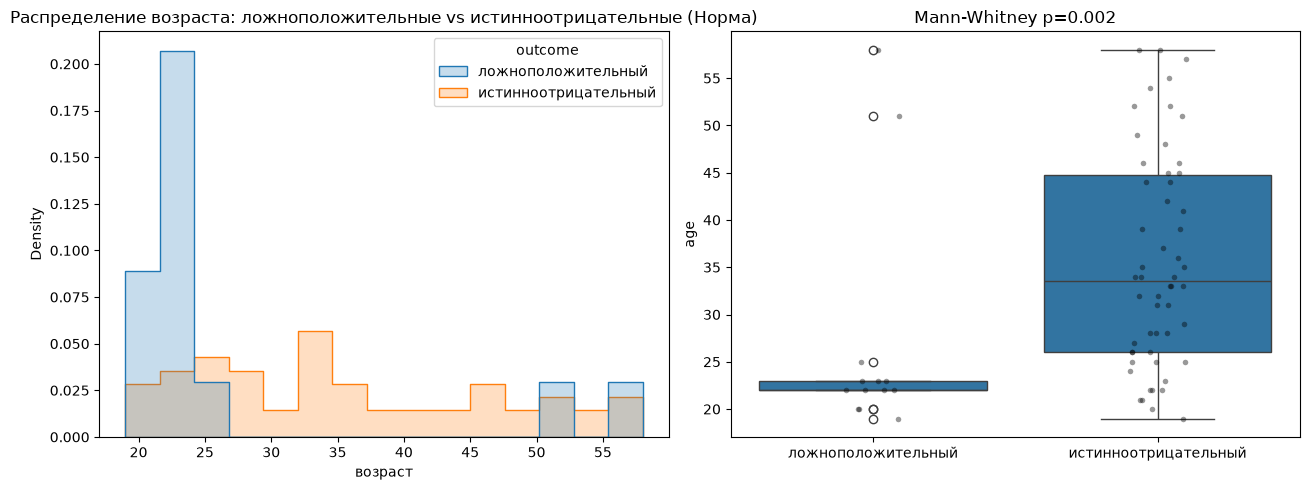

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=norm_loso, x="age", hue="outcome", bins=15,
             element="step", stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Распределение возраста: ложноположительные vs истинноотрицательные (Норма)")
axes[0].set_xlabel("возраст")

sns.boxplot(data=norm_loso, x="outcome", y="age", ax=axes[1])
sns.stripplot(data=norm_loso, x="outcome", y="age", color="black", alpha=0.4, size=4, ax=axes[1])
axes[1].set_title(f"Mann-Whitney p={p_val:.3f}")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

### Итоги

Прямое предсказание возраста по признакам слабое. r=0.131, MAE=10 лет при разбросе возраста 19–58, линейная регрессия по всем 15 признакам почти не восстанавливает возраст. 

Но фактический скор модели внутри Нормы сильно и значимо связан с возрастом. Mann-Whitney p=0.002, медиана возраста ложноположительных  22 года против 34 у истинноотрицательных. И главное эффект не размазан по всему диапазону, а сконцентрирован на одном крае: 43.5% ложноположительных в возрастной группе 19–25, и почти ноль (0% и 8.7%) в двух более старших группах.

Эти два результата не противоречат друг другу. Ridge-регрессия проверяет можно ли линейно восстановить возраст по всему диапазону 19–58 и не может, потому что реальный эффект не линейный, а пороговый: он проявляется резко именно у самых молодых (<26 лет), а дальше пропадает. 

Усреднённая по всему диапазону линейная модель такой локализованный эффект размывает и даёт слабую общую корреляцию, тогда как прямое сравнение крайних групп (ложноположительные vs истинноотрицательные) этот эффект отчётливо вскрывает. 

Итого, возраст не является общим линейным конфаундером для всех признаков, но конкретно для самых молодых испытуемых модель систематически путает их с ПТСР.

Поведенческий показатель (время решения таблиц) слабый, но не нулевой эффект, и только в Норме. r=0.247 в Норме против почти нулевой корреляции в ПТСР (-0.106) и Соматоформных (-0.013). Такая асимметрия сама по себе интересна: если бы скор дублировал время решения напрямую, эффект был бы похожим во всех группах. То, что связь видна только в Норме, правдоподобно объясняется тем же возрастным механизмом: молодые обычно решают таблицы быстрее, и часть этой корреляции может быть не прямым влиянием времени на скор, а побочным следствием того, что и время, и скор одновременно зависят от возраста.